# UTS Graf Sains Data

| | |
|---|---|
| **Nama** | Muhammad Zaky Taj Aldien |
| **NIM** | 23031554065 |
| **Ujian** | UTS Gasal 2026/2027 (Minggu ke-8/9), sifat individu |
| **Dataset** | RetailRocket e-commerce (`events.csv`), sumber: Roman Zykov |
| **Periode saya** | Training (P1): 13 Mei 2015 – 13 Juli 2015 · Testing (P2): 22 Juli 2015 – 6 Agustus 2015 |

## Ringkasan Asumsi dan Keputusan Desain

Naskah soal tidak menentukan beberapa hal berikut, sehingga saya menetapkannya sendiri dan menjelaskannya di bagian terkait.

| Hal | Keputusan | Bagian |
|---|---|---|
| Zona waktu | UTC; `timestamp` adalah Unix epoch dalam **milidetik** | 2.1 No. 1 |
| Bobot interaksi (VSM) | VIEWED = 1, ADDED_TO_CART = 3, BOUGHT = 5, dijumlahkan jika berulang | 2.1 No. 4 |
| Proyeksi yang dipakai | **Item-Item** (lebih efisien dan lebih informatif) | 2.1 No. 6 |
| Similarity | Cosine pada vektor ter-normalisasi L2; user dengan > 100 item dibuang; item minimal 2 user; top-10 tetangga per item | 2.1 No. 7 |
| Item acuan | Persentil ke-90 popularitas → **Item 456933** | 2.1 No. 7 |
| KNN | **Item-based**, k = 5, memakai relasi `SIMILAR_TO` | 2.2 No. 1 |
| "3 item iklan" vs "@5" | Top-5 dihitung untuk metrik; 3 teratas diiklankan | 2.2 No. 1–2 |
| Ground truth | Item yang berinteraksi dengan user di P2 dan belum ada di riwayat P1-nya | 2.2 No. 2 |

In [1]:
import os
import numpy as np
import pandas as pd
import scipy.sparse as sp
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from tqdm.auto import tqdm
from neo4j import GraphDatabase

os.makedirs("data", exist_ok=True)
os.makedirs("gambar", exist_ok=True)

---
# 1. Tugas Pendahuluan

## 1.1 Persiapan dan Perkenalan Lingkungan

- **Virtual environment:** dibuat dengan `python -m venv myvenv`, lalu diaktifkan (di Windows PowerShell: `myvenv\Scripts\Activate.ps1`). Kernel notebook ini memakai environment tersebut.
- **Dependensi:** `neo4j>=5.8`, `pandas`, `numpy`, `scipy`, `scikit-learn`, `networkx`, `matplotlib`, `tqdm`, `jupyter`.
- **Penyimpangan dari `requirements.txt` di soal:** file itu memaksa `neo4j==4.2.1`, padahal kode tutorial 1.2 memakai `driver.execute_query`, parameter `database_`, dan `RoutingControl`, yang baru tersedia di driver 5.x ke atas. Paket `imdbpy`, `nose`, `cinemagoerng`, dan `imdbinfo` tidak dipakai pada soal ini, sehingga tidak dipasang.
- **Server:** Neo4j Desktop (Community Edition) dengan satu instance lokal, diakses lewat `bolt://localhost:7687`. Memori heap dan page cache dibatasi karena RAM laptop terbatas.

## 1.2 Mempelajari Penggunaan Driver Neo4j

Skrip tutorial (`tutorial_neo4j.py`) membuat graf pertemanan `Arthur → Guinevere, Lancelot, Merlin` dengan `MERGE`. Hasilnya adalah 4 simpul `Person` dan 3 relasi `KNOWS` (terlihat pada pesan *Deleted 4 nodes, deleted 3 relationships* saat database dikosongkan sebelum impor RetailRocket).

**Jawaban pertanyaan pendahuluan (checkpoint)**

1. **Nama database pada tutorial:** `neo4j` (database default), terlihat dari argumen `database_="neo4j"` pada `execute_query`.
2. **Akses lain untuk database lain dalam satu instance:**
   - Python: ubah `database_="namadb"` pada `execute_query`, atau buka `driver.session(database="namadb")`.
   - Cypher: `USE namadb MATCH (n) RETURN n;`.
   - Administrasi lewat database `system`: `SHOW DATABASES`, `CREATE DATABASE namadb`, `DROP DATABASE namadb`. Pada Community Edition hanya ada `neo4j` dan `system`.
3. **Jenis graf pertemanan:** graf **berarah** (`(a)-[:KNOWS]->(friend)`), **homogen** (satu label simpul `Person` dan satu tipe relasi `KNOWS`), **tidak berbobot**, dan sederhana (`MERGE` mencegah relasi ganda). Bentuknya *star graph*: Arthur sebagai pusat dengan tiga sisi keluar.

## 1.3 Impor Data RetailRocket ke Neo4j

Dataset diunduh dari Kaggle (`retailrocket/ecommerce-dataset`) dan hanya `events.csv` yang dipakai.

| Kolom | Arti |
|---|---|
| `timestamp` | Waktu kejadian, Unix epoch (milidetik) |
| `visitorid` | ID unik pengunjung → simpul `Visitor` |
| `event` | `view`, `addtocart`, atau `transaction` |
| `itemid` | ID unik produk → simpul `Item` |
| `transactionid` | ID transaksi, hanya terisi untuk event `transaction` |

**Model graf:** `(Visitor)-[:VIEWED]->(Item)`, `(Visitor)-[:ADDED_TO_CART]->(Item)`, `(Visitor)-[:BOUGHT {transactionId}]->(Item)`.

Impor dilakukan oleh skrip `import_retailrocket.py` yang melengkapi kerangka di soal: `batch_size`, `total_rows`, dan `create_constraints` yang masih kosong; dan constraint *unique* pada `Visitor.visitorId` dan `Item.itemId` agar `MERGE` cepat.

---
# 2.1 Wrangling dan EDA

## No. 1: Penentuan periode waktu

| Fold | Mulai | Hingga |
|---|---|---|
| Training (P1) | 13 Mei 2015 | 13 Juli 2015 |
| Testing (P2) | 22 Juli 2015 | 6 Agustus 2015 |

- `timestamp` adalah Unix epoch dalam **milidetik**, dikonversi ke zona waktu **UTC**.
- Batas akhir bersifat inklusif sampai pukul 23:59:59 pada hari terakhir (di kode: `< tanggal berikutnya 00:00`).
- Ada jeda 8 hari (14–21 Juli) antara P1 dan P2, sehingga kedua fold tidak beririsan dan tidak ada kebocoran data. P1 dipakai membangun graf dan similarity; P2 hanya dipakai sebagai *ground truth* evaluasi.

In [2]:
df = pd.read_csv("data/events.csv", dtype={"transactionid": "string"})
df["datetime"] = pd.to_datetime(df["timestamp"], unit="ms", utc=True)

print("Rentang data :", df["datetime"].min(), "->", df["datetime"].max())
print("Jumlah baris :", len(df))
df.head()

Rentang data : 2015-05-03 03:00:04.384000+00:00 -> 2015-09-18 02:59:47.788000+00:00
Jumlah baris : 2756101


,timestamp,visitorid,event,itemid,transactionid,datetime
0,1433221332117,257597,view,355908,<NA>,2015-06-02 05:02:12.117000+00:00
1,1433224214164,992329,view,248676,<NA>,2015-06-02 05:50:14.164000+00:00
2,1433221999827,111016,view,318965,<NA>,2015-06-02 05:13:19.827000+00:00
3,1433221955914,483717,view,253185,<NA>,2015-06-02 05:12:35.914000+00:00
4,1433221337106,951259,view,367447,<NA>,2015-06-02 05:02:17.106000+00:00


In [3]:
P1_START = pd.Timestamp("2015-05-13", tz="UTC")
P1_END   = pd.Timestamp("2015-07-14", tz="UTC")   # eksklusif
P2_START = pd.Timestamp("2015-07-22", tz="UTC")
P2_END   = pd.Timestamp("2015-08-07", tz="UTC")   # eksklusif

train = df[(df["datetime"] >= P1_START) & (df["datetime"] < P1_END)]
test  = df[(df["datetime"] >= P2_START) & (df["datetime"] < P2_END)]

print(f"Training (P1): {len(train):,} baris")
print(f"Testing  (P2): {len(test):,} baris")

Training (P1): 1,297,800 baris
Testing  (P2): 354,068 baris


In [4]:
print(train["event"].value_counts())

event
view           1255750
addtocart        31610
transaction      10440
Name: count, dtype: int64


Rentang data asli adalah 3 Mei – 18 September 2015 (2.756.101 baris). Periode saya berada di dalam rentang tersebut: **P1 = 1.297.800 baris** (1.255.750 view, 31.610 addtocart, 10.440 transaction) dan **P2 = 354.068 baris**.

## No. 2: Terapkan filter dan simpan ke CSV
Hasil filter disimpan dengan kolom yang sama seperti `events.csv`, sehingga file P1 dapat langsung diimpor ke Neo4j oleh skrip 1.3.

In [4]:
cols = ["timestamp", "visitorid", "event", "itemid", "transactionid"]
train[cols].to_csv("data/events_train_P1.csv", index=False)
test[cols].to_csv("data/events_test_P2.csv", index=False)
print("Tersimpan: data/events_train_P1.csv dan data/events_test_P2.csv")

Tersimpan: data/events_train_P1.csv dan data/events_test_P2.csv


## No. 3: Komposisi subgraph
Subgraph dari data P1 diimpor ke Neo4j dengan model graf **bipartit**:

- Simpul `Visitor` (properti `visitorId`) dan `Item` (properti `itemId`).
- Relasi `VIEWED`, `ADDED_TO_CART`, dan `BOUGHT` dari Visitor ke Item.

Komposisi dihitung dengan Cypher melalui Python API (`driver.execute_query`) di bawah ini.

In [5]:
URI = "bolt://localhost:7687"
AUTH = ("neo4j", "password123")

driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()
print("Terhubung")

Terhubung


In [6]:
q_nodes = """
MATCH (n)
RETURN labels(n)[0] AS jenis_simpul, count(n) AS jumlah
ORDER BY jumlah DESC
"""
records, _, _ = driver.execute_query(q_nodes, database_="neo4j")
df_nodes = pd.DataFrame([r.data() for r in records])
df_nodes

,jenis_simpul,jumlah
0,Visitor,661917
1,Item,169813


In [7]:
q_rels = """
MATCH (:Visitor)-[r]->(:Item)
RETURN type(r) AS jenis_relasi, count(r) AS jumlah
ORDER BY jumlah DESC
"""
records, _, _ = driver.execute_query(q_rels, database_="neo4j")
df_rels = pd.DataFrame([r.data() for r in records])
df_rels

,jenis_relasi,jumlah
0,VIEWED,1255750
1,ADDED_TO_CART,31610
2,BOUGHT,10440


In [9]:
print("Total relasi Neo4j :", df_rels["jumlah"].sum())
print("Baris CSV P1       :", len(train))
print(train["event"].value_counts())

Total relasi Neo4j : 1297800
Baris CSV P1       : 1297800
event
view           1255750
addtocart        31610
transaction      10440
Name: count, dtype: int64


**Penjelasan Cypher**

- `MATCH (n)` mencocokkan semua simpul di graf.
- `labels(n)[0]` mengambil label pertama tiap simpul (`Visitor` atau `Item`).
- `count(n)` menghitung simpul per label; Cypher otomatis mengelompokkan berdasarkan kolom non-agregat (`jenis_simpul`), seperti `GROUP BY` di SQL.
- `MATCH (:Visitor)-[r]->(:Item)` mencocokkan semua relasi berarah dari Visitor ke Item, lalu `type(r)` mengambil nama tipe relasinya.
- `ORDER BY jumlah DESC` mengurutkan dari yang terbanyak.

**Hasil:** 661.917 Visitor, 169.813 Item, dan 1.297.800 relasi (1.255.750 VIEWED, 31.610 ADDED_TO_CART, 10.440 BOUGHT). Total relasi di Neo4j sama dengan jumlah baris CSV P1, sehingga impor bersih (tidak ada baris hilang atau ganda).

## No. 4: VSM untuk simpul User (Visitor)
Setiap Visitor direpresentasikan sebagai vektor pada ruang Item. Nilai tiap elemen adalah bobot interaksi: VIEWED = 1, ADDED_TO_CART = 3, BOUGHT = 5 (dijumlahkan bila berulang). Bobot ini dipilih karena pembelian mencerminkan minat yang lebih kuat daripada sekadar melihat. Data diambil dari Neo4j dengan Cypher, lalu disimpan sebagai matriks **sparse** (CSR).

In [10]:
q_edges = """
MATCH (v:Visitor)-[r]->(i:Item)
WITH v.visitorId AS u, i.itemId AS it,
     sum(CASE type(r)
           WHEN 'VIEWED' THEN 1
           WHEN 'ADDED_TO_CART' THEN 3
           WHEN 'BOUGHT' THEN 5
         END) AS w
RETURN u, it, w
"""

us, its, ws = [], [], []
with driver.session(database="neo4j") as session:
    for rec in session.run(q_edges):
        us.append(rec["u"]); its.append(rec["it"]); ws.append(rec["w"])

edges = pd.DataFrame({"u": us, "it": its, "w": ws})
del us, its, ws
print("Pasangan unik (user, item):", len(edges))
edges.head()

Pasangan unik (user, item): 1004794


,u,it,w
0,257597,355908,1
1,981382,355908,1
2,62710,355908,1
3,979686,355908,1
4,479732,355908,1


In [11]:
user_idx, user_ids = pd.factorize(edges["u"])
item_idx, item_ids = pd.factorize(edges["it"])

X_user = sp.csr_matrix(
    (edges["w"].to_numpy(dtype=np.float32), (user_idx, item_idx)),
    shape=(len(user_ids), len(item_ids)),
)
print("Shape X_user :", X_user.shape)

Shape X_user : (661917, 169813)


In [12]:
n_row, n_col = X_user.shape
nnz = X_user.nnz
density = nnz / (n_row * n_col)
dense_gb = n_row * n_col * 4 / 1e9
sparse_mb = (X_user.data.nbytes + X_user.indices.nbytes + X_user.indptr.nbytes) / 1e6

print(f"Dimensi vektor (jumlah item) : {n_col:,}")
print(f"Jumlah vektor (user)         : {n_row:,}")
print(f"Shape                        : {X_user.shape}")
print(f"Elemen non-nol (nnz)         : {nnz:,}")
print(f"Density                      : {density:.8%}")
print(f"Sparsity                     : {1 - density:.6%}")
print(f"Memori jika padat            : {dense_gb:,.1f} GB")
print(f"Memori sparse (CSR)          : {sparse_mb:,.1f} MB")

item_per_user = np.diff(X_user.indptr)
print("\nJumlah item berbeda per user:")
print(pd.Series(item_per_user).describe(percentiles=[.5, .9, .99]))
print(f"User dengan hanya 1 item: {(item_per_user == 1).mean():.2%}")

Dimensi vektor (jumlah item) : 169,813
Jumlah vektor (user)         : 661,917
Shape                        : (661917, 169813)
Elemen non-nol (nnz)         : 1,004,794
Density                      : 0.00089393%
Sparsity                     : 99.999106%
Memori jika padat            : 449.6 GB
Memori sparse (CSR)          : 10.7 MB

Jumlah item berbeda per user:
count    661917.000000
mean          1.518006
std           5.804675
min           1.000000
50%           1.000000
90%           2.000000
99%           8.000000
max        1565.000000
dtype: float64
User dengan hanya 1 item: 79.98%


**Plot networkx (sampel).** Seluruh graf (±830 ribu simpul) tidak mungkin digambar, sehingga ditampilkan sampel acak yang dapat direproduksi (`seed=42`): 6 user dengan minimal 3 interaksi beserta maksimal 4 item dengan bobot tertinggi.

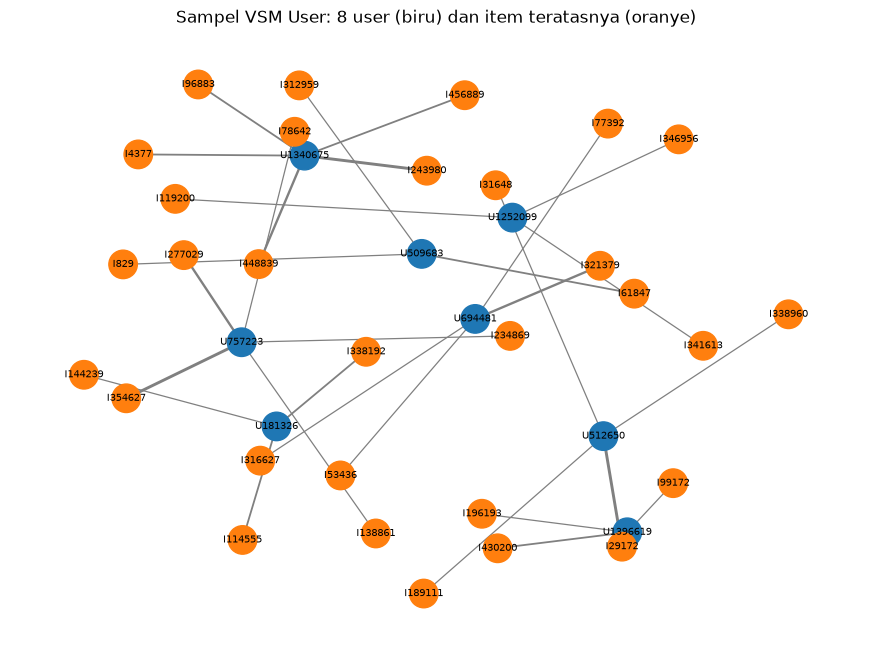

In [14]:
import networkx as nx
import matplotlib.pyplot as plt

def plot_sample(M, row_names, col_names, row_prefix, col_prefix,
                n_rows=8, max_cols=5, seed=42, title=""):
    rng = np.random.default_rng(seed)
    kandidat = np.where(np.diff(M.indptr) >= 3)[0]   # baris dengan >= 3 interaksi
    terpilih = rng.choice(kandidat, size=n_rows, replace=False)

    G = nx.Graph()
    for r in terpilih:
        s, e = M.indptr[r], M.indptr[r + 1]
        cols, vals = M.indices[s:e], M.data[s:e]
        top = np.argsort(-vals)[:max_cols]
        for c, w in zip(cols[top], vals[top]):
            G.add_edge(f"{row_prefix}{row_names[r]}", f"{col_prefix}{col_names[c]}", weight=float(w))

    warna = ["tab:blue" if n.startswith(row_prefix) else "tab:orange" for n in G.nodes]
    lebar = [0.5 + 0.4 * G[a][b]["weight"] for a, b in G.edges]
    pos = nx.spring_layout(G, seed=42, k=0.8)

    plt.figure(figsize=(11, 8))
    nx.draw_networkx(G, pos, node_color=warna, width=lebar, node_size=420,
                     font_size=7, edge_color="gray")
    plt.title(title)
    plt.axis("off")
    plt.show()
    return G

G_user = plot_sample(X_user, user_ids, item_ids, "U", "I",
                     title="Sampel VSM User: 8 user (biru) dan item teratasnya (oranye)")

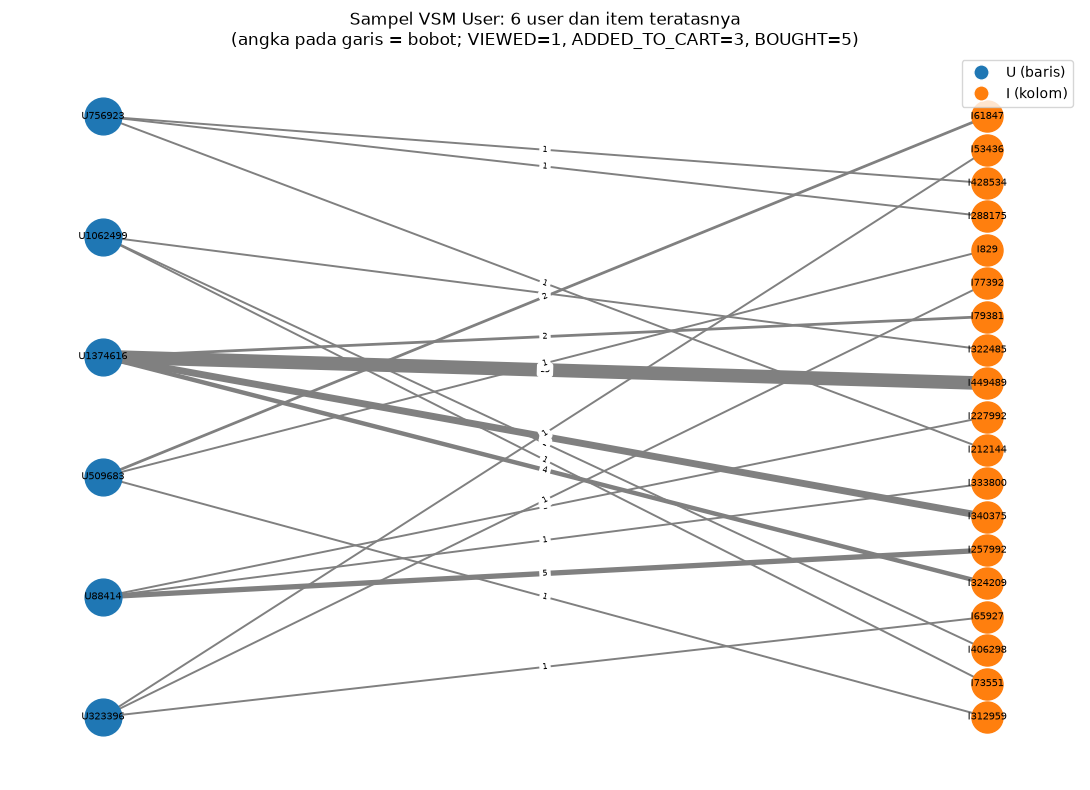

In [13]:
def plot_bipartite(M, row_names, col_names, row_prefix, col_prefix,
                   n_rows=6, max_cols=4, seed=42, title=""):
    rng = np.random.default_rng(seed)
    kandidat = np.where(np.diff(M.indptr) >= 3)[0]
    terpilih = rng.choice(kandidat, size=n_rows, replace=False)

    G = nx.Graph()
    kiri = []
    for r in terpilih:
        s, e = M.indptr[r], M.indptr[r + 1]
        cols, vals = M.indices[s:e], M.data[s:e]
        top = np.argsort(-vals)[:max_cols]
        a = f"{row_prefix}{row_names[r]}"
        G.add_node(a, bipartite=0); kiri.append(a)
        for c, w in zip(cols[top], vals[top]):
            b = f"{col_prefix}{col_names[c]}"
            G.add_node(b, bipartite=1)
            G.add_edge(a, b, weight=int(w))

    kanan = [n for n in G.nodes if n not in kiri]
    pos = nx.bipartite_layout(G, kiri, align="vertical", scale=2)

    plt.figure(figsize=(11, 8))
    nx.draw_networkx_nodes(G, pos, nodelist=kiri, node_color="tab:blue", node_size=700)
    nx.draw_networkx_nodes(G, pos, nodelist=kanan, node_color="tab:orange", node_size=500)
    nx.draw_networkx_edges(G, pos,
        width=[0.8 + 0.6 * G[a][b]["weight"] for a, b in G.edges], edge_color="gray")
    nx.draw_networkx_labels(G, pos, font_size=7)
    nx.draw_networkx_edge_labels(G, pos,
        edge_labels={(a, b): d["weight"] for a, b, d in G.edges(data=True)}, font_size=6)

    plt.legend(handles=[
        Line2D([0],[0], marker="o", color="w", markerfacecolor="tab:blue", markersize=11, label=f"{row_prefix} (baris)"),
        Line2D([0],[0], marker="o", color="w", markerfacecolor="tab:orange", markersize=11, label=f"{col_prefix} (kolom)"),
    ], loc="upper right")
    plt.title(title + "\n(angka pada garis = bobot; VIEWED=1, ADDED_TO_CART=3, BOUGHT=5)")
    plt.axis("off"); plt.tight_layout(); plt.show()

plot_bipartite(X_user, user_ids, item_ids, "U", "I",
               title="Sampel VSM User: 6 user dan item teratasnya")

**Karakteristik VSM User**

- **Dimensi vektor:** 169.813 (satu dimensi per Item). **Jumlah vektor:** 661.917 (satu per Visitor). **Shape:** (661.917 × 169.813).
- **Isi sel:** bobot interaksi (1/3/5, dijumlahkan jika berulang). 1.297.800 relasi menjadi **1.004.794 pasangan unik** (user, item) karena interaksi berulang digabung.
- **Sparsity:** density 0,00089% (99,9991% sel bernilai nol). Matriks padat akan butuh sekitar **449,6 GB**, sedangkan bentuk sparse (CSR) hanya **10,7 MB**. Karena itu `scipy.sparse` wajib dipakai.
- **Distribusi:** median 1 item per user, 90% user ≤ 2 item, 99% ≤ 8 item, maksimum 1.565 item. Sebanyak **79,98% user hanya berinteraksi dengan 1 item**, sehingga vektor user sangat pendek dibanding dimensinya (*long tail*).
- **Plot:** biru = User, oranye = Item, angka dan ketebalan garis = bobot (jumlah bobot interaksi, bisa lebih dari 5 jika berulang). Plot hanya sampel ilustrasi, bukan seluruh graf, dan sampel dibatasi pada user dengan ≥ 3 interaksi sehingga lebih aktif dari rata-rata.

## No. 5: VSM untuk simpul Item
Setiap Item direpresentasikan sebagai vektor pada ruang Visitor. Matriksnya adalah transpos matriks User × Item, sehingga berisi informasi yang sama dengan sudut pandang berbeda.

In [15]:
X_item = X_user.T.tocsr()

n_row_i, n_col_i = X_item.shape
user_per_item = np.diff(X_item.indptr)

print(f"Dimensi vektor (jumlah user) : {n_col_i:,}")
print(f"Jumlah vektor (item)         : {n_row_i:,}")
print(f"Shape                        : {X_item.shape}")
print(f"Elemen non-nol (nnz)         : {X_item.nnz:,}")
print(f"Density                      : {X_item.nnz / (n_row_i * n_col_i):.8%}")
print(f"Memori sparse (CSR)          : {(X_item.data.nbytes + X_item.indices.nbytes + X_item.indptr.nbytes)/1e6:,.1f} MB")

print("\nJumlah user berbeda per item:")
print(pd.Series(user_per_item).describe(percentiles=[.5, .9, .99]))
print(f"Item dengan hanya 1 user: {(user_per_item == 1).mean():.2%}")

Dimensi vektor (jumlah user) : 661,917
Jumlah vektor (item)         : 169,813
Shape                        : (169813, 661917)
Elemen non-nol (nnz)         : 1,004,794
Density                      : 0.00089393%
Memori sparse (CSR)          : 8.7 MB

Jumlah user berbeda per item:
count    169813.000000
mean          5.917062
std          15.380006
min           1.000000
50%           2.000000
90%          13.000000
99%          63.000000
max        1304.000000
dtype: float64
Item dengan hanya 1 user: 41.38%


**Plot networkx (sampel):** 6 item dengan minimal 3 user beserta maksimal 4 user dengan bobot tertinggi (`seed=42`).

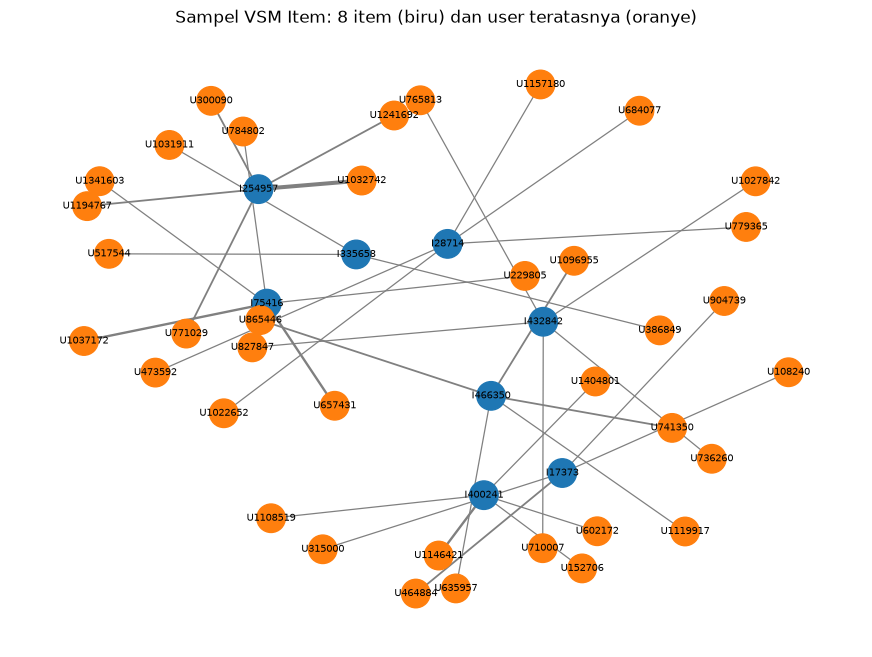

In [16]:
G_item = plot_sample(X_item, item_ids, user_ids, "I", "U", n_rows=8, max_cols=5,
                     title="Sampel VSM Item: 8 item (biru) dan user teratasnya (oranye)")

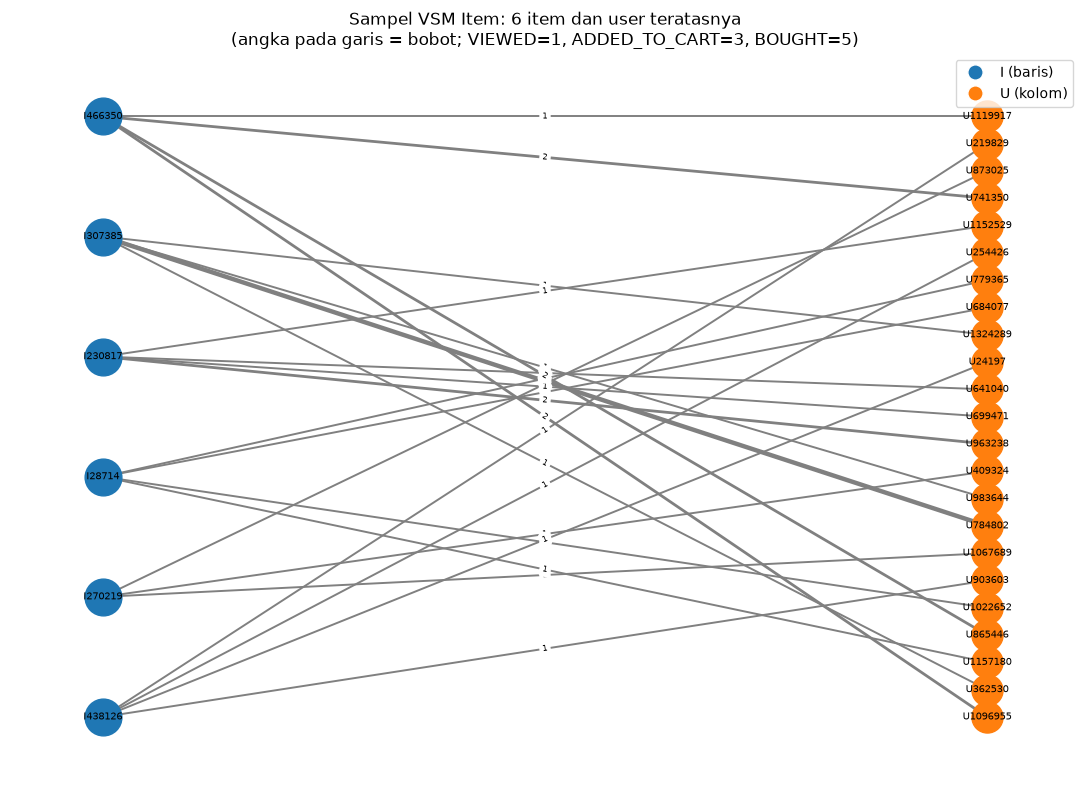

In [20]:
plot_bipartite(X_item, item_ids, user_ids, "I", "U",
               title="Sampel VSM Item: 6 item dan user teratasnya")

**Karakteristik VSM Item**

- **Dimensi vektor:** 661.917 (satu dimensi per Visitor). **Jumlah vektor:** 169.813. **Shape:** (169.813 × 661.917), yaitu transpos dari VSM User, dengan elemen non-nol dan density yang sama (1.004.794 dan 0,00089%).
- **Memori sparse:** 8,7 MB (sedikit lebih kecil dari 10,7 MB karena array `indptr` lebih pendek).
- **Distribusi:** rata-rata **5,92 user per item** (user hanya 1,52 item), median 2, 90% ≤ 13, 99% ≤ 63, maksimum 1.304. Sebanyak **41,38% item hanya punya 1 user**.
- **Perbandingan dengan VSM User:** vektor Item membawa lebih banyak sinyal per vektor, tetapi tetap sangat sparse dan *long tail*.

## No. 6: Proyeksi mana yang lebih baik?
Graf bipartit Visitor-Item dapat diproyeksikan ke graf **User-User** (dua visitor terhubung bila berinteraksi dengan item yang sama; matriks `X_user @ X_user.T`) atau graf **Item-Item** (dua item terhubung bila diinteraksi visitor yang sama; matriks `X_item @ X_item.T`).

Satu simpul berderajat `d` di sisi lawan menghasilkan `d(d−1)/2` pasangan, sehingga jumlah sisi proyeksi dapat diestimasi tanpa membentuk matriksnya (batas atas, karena pasangan yang sama bisa muncul lewat beberapa perantara). Perbandingan dilakukan pada ukuran matriks, estimasi sisi, memori, simpul terisolasi, dan dominasi simpul super aktif.

In [17]:
B = X_user.copy()
B.data[:] = 1                       # biner: ada/tidaknya interaksi
user_deg = np.asarray(B.sum(axis=1)).ravel()   # jumlah item per user
item_deg = np.asarray(B.sum(axis=0)).ravel()   # jumlah user per item

def pairs(deg):
    return int((deg * (deg - 1) / 2).sum())

# Jumlah pasangan (batas atas sisi proyeksi)
pairs_item = pairs(user_deg)   # Item-Item: dibentuk lewat user
pairs_user = pairs(item_deg)   # User-User: dibentuk lewat item

n_u, n_i = B.shape
def ringkas(nama, n, pasangan):
    sel = n * n
    nnz = 2 * pasangan                  # simetris: (a,b) dan (b,a)
    return {
        "Proyeksi": nama,
        "Shape": f"{n:,} x {n:,}",
        "Sel total": f"{sel:.2e}",
        "Pasangan (batas atas)": f"{pasangan:,}",
        "Density (batas atas)": f"{nnz / sel:.4%}",
        "Memori sparse (GB)": round(nnz * 8 / 1e9, 2),
        "Memori padat (GB)": round(sel * 4 / 1e9, 1),
    }

tabel = pd.DataFrame([
    ringkas("User-User", n_u, pairs_user),
    ringkas("Item-Item", n_i, pairs_item),
]).set_index("Proyeksi").T
display(tabel)

# Simpul terisolasi di graf proyeksi
user_ok = (user_deg > 1).astype(np.float32)   # user yang bisa menghubungkan item
item_ok = (item_deg > 1).astype(np.float32)   # item yang bisa menghubungkan user
item_punya_tetangga = (B.T @ user_ok) > 0
user_punya_tetangga = (B @ item_ok) > 0
print(f"Item terisolasi di proyeksi Item-Item: {(~item_punya_tetangga).mean():.2%}")
print(f"User terisolasi di proyeksi User-User: {(~user_punya_tetangga).mean():.2%}")

# Dominasi simpul super aktif
print("\nSatu user terbanyak menghasilkan pasangan item:",
      f"{int(user_deg.max() * (user_deg.max() - 1) / 2):,}",
      f"({user_deg.max() * (user_deg.max() - 1) / 2 / pairs_item:.2%} dari total)")
print("Satu item terpopuler menghasilkan pasangan user:",
      f"{int(item_deg.max() * (item_deg.max() - 1) / 2):,}",
      f"({item_deg.max() * (item_deg.max() - 1) / 2 / pairs_user:.2%} dari total)")

Proyeksi,User-User,Item-Item
Shape,"661,917 x 661,917","169,813 x 169,813"
Sel total,4.38e+11,2.88e+10
Pasangan (batas atas),"22,554,372","11,411,625"
Density (batas atas),0.0103%,0.0791%
Memori sparse (GB),0.36,0.18
Memori padat (GB),1752.5,115.3


Item terisolasi di proyeksi Item-Item: 39.18%
User terisolasi di proyeksi User-User: 6.77%

Satu user terbanyak menghasilkan pasangan item: 1,223,830 (10.72% dari total)
Satu item terpopuler menghasilkan pasangan user: 849,556 (3.77% dari total)


In [18]:
# Stabilitas P1 -> P2: seberapa banyak entitas di P2 yang sudah dikenal di P1?
vis_p1, vis_p2 = set(train["visitorid"]), set(test["visitorid"])
itm_p1, itm_p2 = set(train["itemid"]), set(test["itemid"])

print(f"Visitor P2 yang sudah ada di P1: {len(vis_p1 & vis_p2):,} dari {len(vis_p2):,} "
      f"({len(vis_p1 & vis_p2) / len(vis_p2):.2%})")
print(f"Item    P2 yang sudah ada di P1: {len(itm_p1 & itm_p2):,} dari {len(itm_p2):,} "
      f"({len(itm_p1 & itm_p2) / len(itm_p2):.2%})")

Visitor P2 yang sudah ada di P1: 11,287 dari 195,342 (5.78%)
Item    P2 yang sudah ada di P1: 67,534 dari 86,717 (77.88%)


Sel di atas membandingkan dua rasio: visitor P2 yang sudah dikenal di P1 dan item P2 yang sudah dikenal di P1. Rasio yang lebih tinggi berarti entitas itu lebih stabil sebagai dasar rekomendasi lintas periode.

### Tabel perbandingan

| Aspek | User-User | Item-Item | Unggul |
|---|---|---|---|
| Shape | 661.917² | 169.813² | Item |
| Sel total | 4,38 × 10¹¹ | 2,88 × 10¹⁰ (±15× lebih kecil) | Item |
| Pasangan (batas atas) | 22.554.372 | 11.411.625 (±2× lebih sedikit) | Item |
| Memori sparse (batas atas) | 0,36 GB | 0,18 GB | Item |
| Density (batas atas) | 0,0103% | 0,0791% (±8× lebih rapat) | Item |
| Sinyal per vektor | 1,52 item per user | 5,92 user per item | Item |
| Simpul terisolasi | **6,77%** | **39,18%** | **User** |
| Dominasi satu simpul | 3,77% (item terpopuler) | 10,72% (user terbanyak) | **User** |

### Kesimpulan No. 6
**Proyeksi Item-Item dipilih**, dengan alasan:

1. **Efisien:** matriks sekitar 15× lebih kecil, estimasi pasangan separuhnya, dan density sekitar 8× lebih tinggi.
2. **Efektif untuk rekomendasi:** yang direkomendasikan adalah *item*, sehingga kemiripan item langsung menghasilkan kandidat. Pada proyeksi User-User, 80% user hanya punya 1 item sehingga kemiripannya hampir tidak informatif, sedangkan item rata-rata punya 5,92 user.
3. **Stabilitas lintas periode** dibandingkan pada sel stabilitas di atas.

**Kelemahan Item-Item (tidak disembunyikan):** 39,18% item terisolasi (tidak punya tetangga lewat user yang berinteraksi dengan ≥ 2 item), dan satu user super aktif (1.565 item) menyumbang 10,72% pasangan sehingga dapat membiaskan similarity. Kelemahan kedua ditangani di No. 7 dengan membuang user dengan > 100 item, dan cosine ter-normalisasi mengurangi bias popularitas. Item yang terisolasi tidak dapat direkomendasikan lewat kemiripan; kasus ini dicatat sebagai keterbatasan di No. 7 dan 2.2 (fallback ke item populer tidak diimplementasikan).

## No. 7: Perhitungan similarity pada proyeksi Item-Item

Berdasarkan No. 6, proyeksi **Item-Item** dipilih. Kemiripan antar-Item dihitung dengan **cosine similarity** menggunakan Python, lalu hasilnya ditulis kembali ke graf Neo4j sebagai relasi `SIMILAR_TO`.

### 7.1 Metode

Setiap Item adalah vektor pada ruang Visitor (VSM No. 5, setelah user super aktif dibuang), dengan bobot VIEWED = 1, ADDED_TO_CART = 3, BOUGHT = 5. Kemiripan dua item $a$ dan $b$:

$$
\text{cos}(a, b) = \frac{\vec{a} \cdot \vec{b}}{\lVert \vec{a} \rVert \, \lVert \vec{b} \rVert}
$$

Setiap vektor item dinormalisasi L2 terlebih dahulu sehingga cosine sama dengan *dot product*. Karena semua bobot positif, nilainya berkisar 0 sampai 1: 0 berarti tidak ada visitor yang sama, dan 1 berarti arah vektor visitornya identik. Normalisasi mengurangi bias item populer, karena item yang banyak dilihat tidak otomatis lebih mirip hanya karena jumlah interaksinya besar.

### 7.2 Keputusan desain

| No | Keputusan | Nilai | Alasan |
|---|---|---|---|
| 1 | Batas user super aktif | User dengan > 100 item dibuang | Satu user dengan 1.565 item menghasilkan ±10,72% dari seluruh pasangan item sehingga dapat membiaskan similarity. Hanya 126 user (±0,02%) yang dibuang. |
| 2 | Item kandidat | Minimal 2 user | Item dengan 1 user tidak punya pasangan bermakna. Tersisa 97.498 dari 169.813 item. |
| 3 | Metrik | Cosine, vektor ter-normalisasi L2 | Mengurangi bias popularitas. |
| 4 | Top-k | k = 10 tetangga per item | Menjaga ukuran graf dan memori tetap terkendali. |
| 5 | Cara komputasi | Per blok 2.000 item | Matriks 97.498 × 97.498 tidak pernah dibentuk penuh sehingga muat di RAM. |


In [19]:
MAX_USER_ITEMS = 100
MIN_ITEM_USERS = 2
K = 10
BLOCK = 2000

# 1. buang user super aktif
keep_user = (user_deg <= MAX_USER_ITEMS).astype(np.float32)
W = (sp.diags(keep_user) @ X_user).tocsr()
W.eliminate_zeros()
print(f"User dibuang: {int((keep_user == 0).sum()):,}")

# 2. item kandidat: minimal 2 user
item_deg2 = W.getnnz(axis=0)
cand = np.where(item_deg2 >= MIN_ITEM_USERS)[0]
item_ids_c = np.asarray(item_ids)[cand]
print(f"Item kandidat: {len(cand):,} dari {W.shape[1]:,}")

# 3. normalisasi L2 per kolom (item)
Wc = W[:, cand].tocsr()
norms = np.sqrt(np.asarray(Wc.multiply(Wc).sum(axis=0)).ravel())
Wc = sp.csr_matrix(Wc @ sp.diags(1.0 / norms))

Xi = Wc.T.tocsr()     # item x user
XuT = Wc              # user x item
print("Shape Xi:", Xi.shape, "| nnz:", Xi.nnz)

User dibuang: 126
Item kandidat: 97,498 dari 169,813
Shape Xi: (97498, 661917) | nnz: 896834


In [21]:
A, Bv, S_ = [], [], []
for s in tqdm(range(0, Xi.shape[0], BLOCK), desc="Blok item"):
    e = min(s + BLOCK, Xi.shape[0])
    S = (Xi[s:e] @ XuT).tocsr()
    for r in range(e - s):
        a, b = S.indptr[r], S.indptr[r + 1]
        idx, val = S.indices[a:b], S.data[a:b]
        m = idx != (s + r)                    # buang diri sendiri
        idx, val = idx[m], val[m]
        if len(val) == 0:
            continue
        if len(val) > K:
            top = np.argpartition(-val, K)[:K]
            idx, val = idx[top], val[top]
        o = np.argsort(-val)
        A.append(np.full(len(o), s + r)); Bv.append(idx[o]); S_.append(val[o])

A, Bv, S_ = np.concatenate(A), np.concatenate(Bv), np.concatenate(S_)
df_sim = pd.DataFrame({
    "item_a": item_ids_c[A].astype(np.int64),
    "item_b": item_ids_c[Bv].astype(np.int64),
    "score": np.round(S_, 4),
})
df_sim.to_csv("data/item_similarity_topk.csv", index=False)   # cadangan
print("Pasangan tersimpan :", len(df_sim))
print("Item punya tetangga:", df_sim["item_a"].nunique())
df_sim.head()

Blok item:   0%|          | 0/49 [00:00<?, ?it/s]

Pasangan tersimpan : 457526
Item punya tetangga: 71865


,item_a,item_b,score
0,355908,97139,0.2539
1,355908,259725,0.1951
2,355908,436412,0.1927
3,355908,344469,0.1802
4,355908,238777,0.1699


### 7.3 Hasil perhitungan

- Matriks ter-normalisasi `Xi` berukuran **97.498 × 661.917** dengan 896.834 elemen non-nol.
- Terbentuk **457.526 pasangan** (item_a → item_b) beserta skornya.
- **71.865 item** (73,7% dari item kandidat) memiliki setidaknya satu tetangga. Sisanya (25.633 item) tidak punya tetangga karena visitor-nya tidak berbagi item lain setelah user super aktif dibuang.
- Jumlah pasangan lebih kecil dari batas teoretis (97.498 × 10 = 974.980) karena banyak item memiliki kurang dari 10 tetangga.

**Item acuan.** Dipilih deterministik, yaitu item pada persentil ke-90 popularitas di antara item kandidat: **Item 456933** (19 visitor).

In [22]:
deg_c = Xi.getnnz(axis=1)
ref_pos = np.argsort(deg_c, kind="stable")[int(0.9 * len(deg_c))]
REF_ITEM = int(item_ids_c[ref_pos])
print("Item acuan:", REF_ITEM, "| jumlah user:", int(deg_c[ref_pos]))

top5_py = df_sim[df_sim["item_a"] == REF_ITEM].head(5)
display(top5_py)

# validasi manual cosine untuk tetangga teratas
b_id = int(top5_py.iloc[0]["item_b"])
b_pos = int(np.where(item_ids_c == b_id)[0][0])
manual = Xi[ref_pos].multiply(Xi[b_pos]).sum()
print(f"Cosine manual {REF_ITEM}-{b_id}: {manual:.4f} | tersimpan: {top5_py.iloc[0]['score']}")

Item acuan: 456933 | jumlah user: 19


,item_a,item_b,score
303244,456933,446623,0.2048
303245,456933,59023,0.1741
303246,456933,405981,0.1421
303247,456933,168322,0.1113
303248,456933,100195,0.0987


Cosine manual 456933-446623: 0.2048 | tersimpan: 0.20479999482631683


**Validasi.** Cosine yang dihitung manual untuk pasangan 456933–446623 adalah 0,2048, sama dengan nilai tersimpan.

### No. 7(b): Menuliskan kembali nilai similarity ke graf
Karena query 7(a) membaca relasi `SIMILAR_TO` yang dibuat di sini, 7(b) dijalankan lebih dulu.

```cypher
UNWIND $rows AS row
MATCH (a:Item {itemId: row.a})
MATCH (b:Item {itemId: row.b})
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.score = row.score
```

- `UNWIND $rows AS row` memecah daftar pasangan dari Python menjadi baris yang diproses satu per satu (dikirim per batch 5.000 baris).
- Dua `MATCH` menemukan simpul Item yang sudah ada, sehingga tidak ada simpul baru yang dibuat.
- `MERGE` membuat relasi `SIMILAR_TO` hanya bila belum ada, sehingga aman dijalankan ulang tanpa relasi ganda.
- `SET s.score = row.score` menyimpan nilai cosine sebagai properti relasi.

In [23]:
q_write = """
UNWIND $rows AS row
MATCH (a:Item {itemId: row.a})
MATCH (b:Item {itemId: row.b})
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.score = row.score
"""

def tulis(tx, rows):
    tx.run(q_write, rows=rows).consume()

rows = [{"a": int(a), "b": int(b), "score": float(s)}
        for a, b, s in zip(df_sim["item_a"], df_sim["item_b"], df_sim["score"])]

BATCH = 5000
with driver.session(database="neo4j") as session:
    for i in tqdm(range(0, len(rows), BATCH), desc="Tulis SIMILAR_TO"):
        session.execute_write(tulis, rows[i:i + BATCH])
print("Selesai")

Tulis SIMILAR_TO:   0%|          | 0/92 [00:00<?, ?it/s]

Selesai


### No. 7(a): Cypher untuk 5 record dengan similarity tertinggi
Record acuan: Item **456933**.

- `MATCH (a:Item {itemId: $ref})` memilih simpul acuan (`$ref` = 456933).
- `-[s:SIMILAR_TO]->(b:Item)` mencari semua item yang terhubung lewat `SIMILAR_TO`; relasinya disimpan di variabel `s` agar properti `score` dapat dibaca.
- `ORDER BY similarity DESC LIMIT 5` mengambil lima skor tertinggi.

In [24]:
q_top5 = """
MATCH (a:Item {itemId: $ref})-[s:SIMILAR_TO]->(b:Item)
RETURN a.itemId AS item_acuan, b.itemId AS item_mirip, s.score AS similarity
ORDER BY similarity DESC
LIMIT 5
"""
rec, _, _ = driver.execute_query(q_top5, ref=REF_ITEM, database_="neo4j")
pd.DataFrame([r.data() for r in rec])

,item_acuan,item_mirip,similarity
0,456933,446623,0.2048
1,456933,59023,0.1741
2,456933,405981,0.1421
3,456933,168322,0.1113
4,456933,100195,0.0987


Lima item teratas dari Neo4j **identik** dengan hasil Python di atas. Jumlah relasi `SIMILAR_TO` di Neo4j setelah verifikasi sama dengan jumlah baris `df_sim`, yaitu **457.526** (lihat Lampiran A).

### 7.5 Interpretasi dan keterbatasan

1. **Skor similarity relatif rendah** (maksimum 0,2048 pada item acuan). Hal ini wajar pada data e-commerce yang sangat sparse: kebanyakan item hanya dilihat sedikit visitor sehingga irisan visitor antar-item kecil. Peringkat relatif tetap bermakna.
2. **Item acuan hanya punya 19 visitor**, sehingga estimasi kemiripannya berbasis sampel kecil dan sensitif terhadap perilaku beberapa visitor.
3. **Cakupan tidak penuh.** Sebanyak **97.948 item (57,7% dari 169.813)** tidak punya tetangga `SIMILAR_TO`: 72.315 item bukan kandidat (kurang dari 2 user setelah user super aktif dibuang) dan 25.633 kandidat yang visitor-nya tidak berbagi item lain. Untuk kasus ini diperlukan strategi cadangan (*fallback*), misalnya item populer; strategi tersebut tidak diimplementasikan di sini.
4. **Pembuangan user super aktif** mengurangi bias, tetapi juga membuang sebagian kecil informasi (126 user).
5. **Similarity dihitung hanya dari data P1.** Kualitasnya diuji di 2.2 memakai data P2 melalui Hit@5 dan NDCG@5.

## No. 8: Kondisi sebelum dan sesudah perhitungan similarity

Pembanding yang dipakai adalah Item acuan **456933**.

- **Sebelum:** item acuan hanya terhubung ke Visitor lewat relasi interaksi (VIEWED, ADDED_TO_CART, BOUGHT). Tidak ada relasi antar-Item; jumlah `SIMILAR_TO` = 0.
- **Sesudah:** item acuan terhubung ke item-item lain lewat `SIMILAR_TO` yang menyimpan skor cosine pada properti `score`.

### Sebelum

,visitor,relasi,item
0,593345,VIEWED,456933
1,1311999,VIEWED,456933
2,1311999,VIEWED,456933
3,1369573,VIEWED,456933
4,1369573,VIEWED,456933
5,1110886,VIEWED,456933
6,1093437,VIEWED,456933
7,689933,VIEWED,456933
8,211370,VIEWED,456933
9,211370,VIEWED,456933


,relasi,jumlah,visitor_unik
0,VIEWED,27,18
1,ADDED_TO_CART,1,1


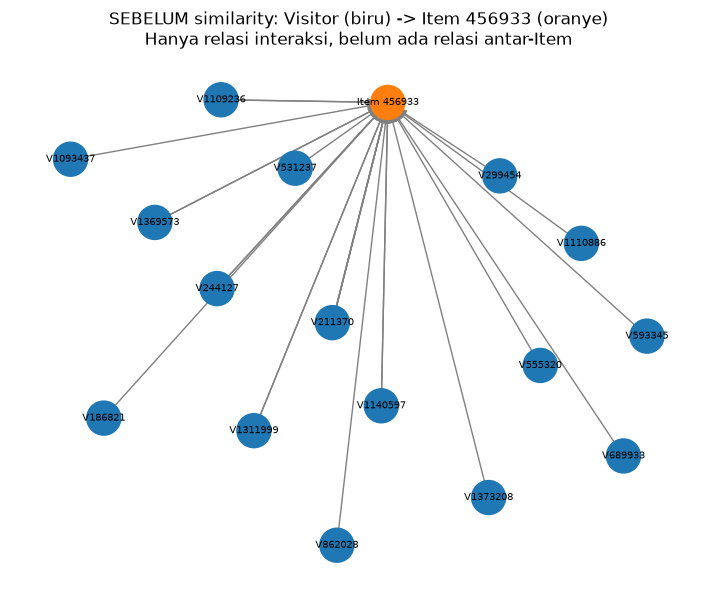

In [25]:
q_before = """
MATCH (v:Visitor)-[r]->(i:Item {itemId: $ref})
WHERE type(r) IN ['VIEWED','ADDED_TO_CART','BOUGHT']
RETURN v.visitorId AS visitor, type(r) AS relasi, i.itemId AS item
LIMIT 25
"""
rec, _, _ = driver.execute_query(q_before, ref=REF_ITEM, database_="neo4j")
df_before = pd.DataFrame([r.data() for r in rec])
display(df_before.head(10))

# Ringkasan tipe relasi item acuan (tanpa SIMILAR_TO)
q_before_sum = """
MATCH (v:Visitor)-[r]->(i:Item {itemId: $ref})
RETURN type(r) AS relasi, count(r) AS jumlah, count(DISTINCT v) AS visitor_unik
"""
rec, _, _ = driver.execute_query(q_before_sum, ref=REF_ITEM, database_="neo4j")
display(pd.DataFrame([r.data() for r in rec]))

# Gambar graf sebelum
G1 = nx.MultiDiGraph()
G1.add_node(f"Item {REF_ITEM}", jenis="item")
for _, row in df_before.iterrows():
    G1.add_edge(f"V{row['visitor']}", f"Item {REF_ITEM}", label=row["relasi"])

pos = nx.spring_layout(G1, seed=42, k=0.9)
warna = ["tab:orange" if n.startswith("Item") else "tab:blue" for n in G1.nodes]
plt.figure(figsize=(9, 7))
nx.draw_networkx_nodes(G1, pos, node_color=warna, node_size=600)
nx.draw_networkx_edges(G1, pos, edge_color="gray", arrows=True, arrowsize=12)
nx.draw_networkx_labels(G1, pos, font_size=7)
plt.title(f"SEBELUM similarity: Visitor (biru) -> Item {REF_ITEM} (oranye)\n"
          "Hanya relasi interaksi, belum ada relasi antar-Item")
plt.axis("off"); plt.show()

Beberapa visitor punya lebih dari satu relasi `VIEWED` ke item yang sama. Contoh: visitor 211370 (diperiksa di bawah). Pada plot di atas garis ganda berimpit sehingga tampak satu garis; plot berikutnya menggambarnya terpisah. Plot dibatasi `LIMIT 25` relasi sehingga hanya sampel dari 19 visitor item ini.

In [26]:
rec, _, _ = driver.execute_query("""
MATCH (v:Visitor {visitorId: 211370})-[r]->(i:Item {itemId: 456933})
RETURN type(r) AS relasi, count(r) AS jumlah
""", database_="neo4j")
print(pd.DataFrame([r.data() for r in rec]))

   relasi  jumlah
0  VIEWED       5


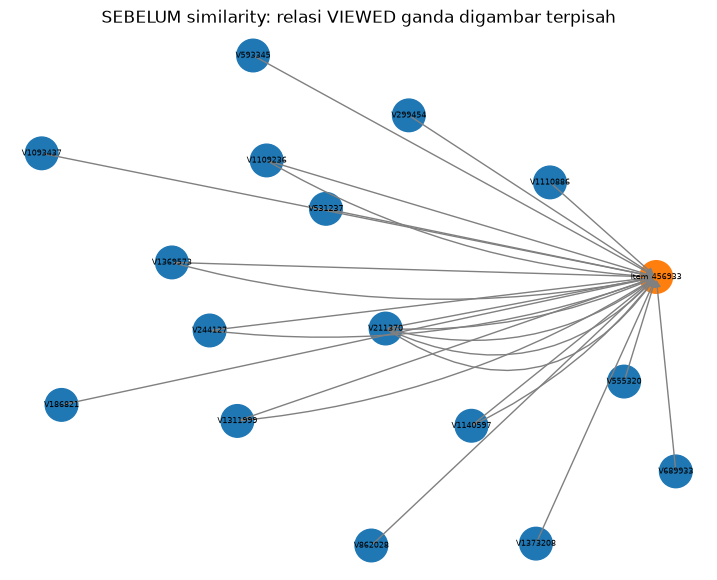

In [27]:
G1 = nx.MultiDiGraph()
ref_label = f"Item {REF_ITEM}"
for _, row in df_before.iterrows():
    G1.add_edge(f"V{int(row['visitor'])}", ref_label)

pos1 = nx.spring_layout(G1, seed=42, k=0.9)
c1 = ["tab:orange" if n == ref_label else "tab:blue" for n in G1.nodes]
plt.figure(figsize=(9, 7))
nx.draw_networkx_nodes(G1, pos1, node_color=c1, node_size=550)
ax = plt.gca()
for (u, v, k) in G1.edges(keys=True):
    ax.annotate("", xy=pos1[v], xytext=pos1[u],
        arrowprops=dict(arrowstyle="-|>", color="gray",
                        connectionstyle=f"arc3,rad={0.12 * k}"))
nx.draw_networkx_labels(G1, pos1, font_size=6)
plt.title("SEBELUM similarity: relasi VIEWED ganda digambar terpisah")
plt.axis("off"); plt.show()

**Bukti dari Neo4j Browser** (screenshot diambil *sebelum* relasi `SIMILAR_TO` ditulis):

```cypher
MATCH ()-[s:SIMILAR_TO]->() RETURN count(s) AS jumlah_similar;
MATCH (v:Visitor)-[r]->(i:Item {itemId: 456933}) RETURN v, r, i LIMIT 25;
```

![Graf sebelum, tampilan bersih (Neo4j Browser)](gambar/no8_sebelum_graf_neo4j_bersih.png)

![jumlah_similar = 0 sebelum penulisan](gambar/no8_sebelum_hitung_similar_0.png)

### Sesudah

,item_acuan,item_mirip,similarity
0,456933,446623,0.2048
1,456933,59023,0.1741
2,456933,405981,0.1421
3,456933,168322,0.1113
4,456933,100195,0.0987


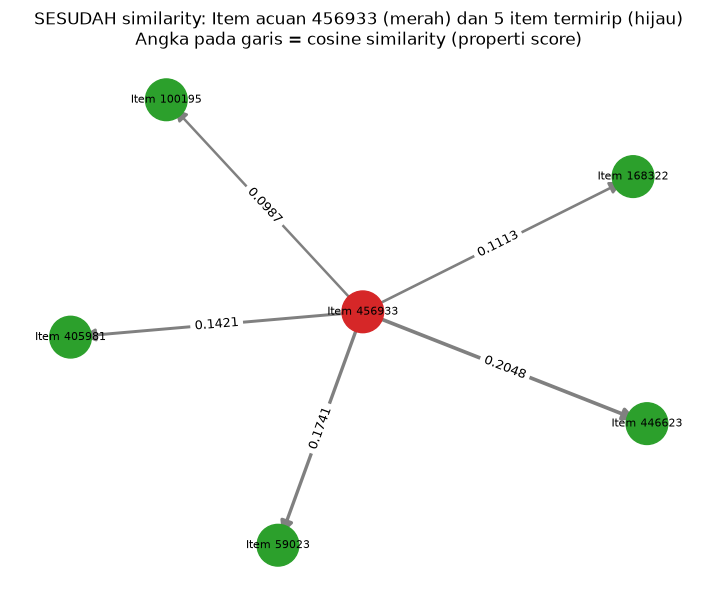

In [28]:
q_after = """
MATCH (a:Item {itemId: $ref})-[s:SIMILAR_TO]->(b:Item)
RETURN a.itemId AS item_acuan, b.itemId AS item_mirip, s.score AS similarity
ORDER BY similarity DESC
LIMIT 5
"""
rec, _, _ = driver.execute_query(q_after, ref=REF_ITEM, database_="neo4j")
df_after = pd.DataFrame([r.data() for r in rec])
display(df_after)

# Gambar graf sesudah, skor tampil di garis
G2 = nx.DiGraph()
for _, row in df_after.iterrows():
    G2.add_edge(f"Item {int(row['item_acuan'])}", f"Item {int(row['item_mirip'])}",
                score=round(float(row["similarity"]), 4))

pos = nx.spring_layout(G2, seed=42, k=1.2)
warna = ["tab:red" if n == f"Item {REF_ITEM}" else "tab:green" for n in G2.nodes]
plt.figure(figsize=(9, 7))
nx.draw_networkx_nodes(G2, pos, node_color=warna, node_size=900)
nx.draw_networkx_edges(G2, pos, edge_color="gray", arrows=True, arrowsize=18,
                       width=[1 + 8 * d["score"] for _, _, d in G2.edges(data=True)])
nx.draw_networkx_labels(G2, pos, font_size=8)
nx.draw_networkx_edge_labels(G2, pos,
    edge_labels={(a, b): d["score"] for a, b, d in G2.edges(data=True)}, font_size=9)
plt.title(f"SESUDAH similarity: Item acuan {REF_ITEM} (merah) dan 5 item termirip (hijau)\n"
          "Angka pada garis = cosine similarity (properti score)")
plt.axis("off"); plt.show()

In [29]:
rec, _, _ = driver.execute_query(
    "MATCH (:Item {itemId:$ref})-[s:SIMILAR_TO]->() RETURN count(s) AS n",
    ref=REF_ITEM, database_="neo4j")
print(f"SIMILAR_TO keluar dari item {REF_ITEM}:", rec[0]["n"])

SIMILAR_TO keluar dari item 456933: 10


Item acuan memiliki 10 relasi `SIMILAR_TO` keluar (top-k = 10); gambar menampilkan 5 teratas.

**Bukti dari Neo4j Browser** (setelah penulisan):

```cypher
MATCH (a:Item {itemId: 456933})-[s:SIMILAR_TO]->(b:Item)
RETURN a, s, b ORDER BY s.score DESC LIMIT 5;
```

![Graf sesudah (Neo4j Browser)](gambar/no8_sesudah_graf_neo4j.png)

Nilai skor tiap relasi ditampilkan pada tabel dan plot Python di atas.

### Perbandingan

| | Sebelum | Sesudah |
|---|---|---|
| Relasi pada Item 456933 | 28 relasi masuk dari Visitor (27 VIEWED dari 18 visitor, 1 ADDED_TO_CART) | 10 relasi `SIMILAR_TO` keluar ke Item lain (5 teratas ditampilkan) |
| Relasi `SIMILAR_TO` di graf | 0 | 457.526 |
| Struktur graf | Bipartit murni (Visitor–Item) | Bipartit + lapisan Item–Item berbobot (`score`) |

Penambahan lapisan Item–Item inilah yang dipakai KNN pada 2.2.

---
# 2.2 Analytics

## No. 1: Rekomendasi KNN (item-based)

**Pendekatan.** Untuk seorang user, setiap item yang pernah diinteraksinya di P1 mencari **k = 5 tetangga terdekat** lewat relasi `SIMILAR_TO`. Skor kandidat = jumlah (bobot interaksi user × similarity). Item yang sudah pernah diinteraksi dikeluarkan. Top-5 menjadi daftar rekomendasi, dan 3 teratas diiklankan.

| Hal | Keputusan | Alasan |
|---|---|---|
| Jenis KNN | Item-based | Konsisten dengan No. 6 dan memakai graf `SIMILAR_TO` yang sudah dibangun |
| Skor kandidat | Σ (bobot interaksi × similarity) | Pembelian (5) berpengaruh lebih besar daripada view (1) |
| Item lama user | Dikeluarkan | Iklan seharusnya berisi item baru |
| "3 item iklan" dan "@5" | Top-5 dihitung, 3 teratas diiklankan | Soal meminta 3 iklan di 1b, tetapi metrik berakhiran @5 (ini asumsi saya) |
| Pemilihan user | Acak, `seed=42`, dari user yang layak | Reproducible |

**Kriteria user layak:** ada di P1 dan P2, punya ≥ 2 item di P1, minimal satu item P1-nya punya tetangga, dan punya minimal satu item baru di P2 yang juga ada di katalog P1. Proses acak: `numpy.random.default_rng(42).choice(...)` pada daftar user layak yang sudah diurutkan.

### No. 1(a): Skrip Python KNN

In [30]:
SEED, K, TOPN = 42, 5, 5

item_arr = np.asarray(item_ids)
user_pos = {u: i for i, u in enumerate(np.asarray(user_ids))}

# tetangga tiap item, urut skor menurun
neigh = {int(a): list(zip(g["item_b"].astype(int), g["score"]))
         for a, g in df_sim.sort_values(["item_a", "score"], ascending=[True, False])
                           .groupby("item_a")}

def riwayat_p1(uid):
    """item dan bobot interaksi user di P1 dari matriks VSM."""
    r = user_pos[uid]
    s, e = X_user.indptr[r], X_user.indptr[r + 1]
    return item_arr[X_user.indices[s:e]].astype(int), X_user.data[s:e]

def recommend(uid, k=K, n=TOPN):
    items, w = riwayat_p1(uid)
    seen = set(items.tolist())
    skor = {}
    for it, wt in zip(items, w):
        for nb, sc in neigh.get(int(it), [])[:k]:
            if nb not in seen:
                skor[nb] = skor.get(nb, 0.0) + float(wt) * float(sc)
    return sorted(skor.items(), key=lambda x: -x[1])[:n]

### Memilih user acak (reproducible)

In [31]:
truth_p2 = test.groupby("visitorid")["itemid"].apply(lambda s: set(s.astype(int)))
katalog = set(item_arr.astype(int).tolist())

def eligible(uid):
    if uid not in user_pos:
        return False
    items, _ = riwayat_p1(uid)
    if len(items) < 2 or not any(int(i) in neigh for i in items):
        return False
    baru = (truth_p2[uid] - set(items.tolist())) & katalog
    return len(baru) > 0

kandidat = sorted(u for u in truth_p2.index if eligible(u))
print("User di P1 dan P2:", len(set(truth_p2.index) & set(user_pos)))
print("User layak       :", len(kandidat))

rng = np.random.default_rng(SEED)
USER = int(rng.choice(kandidat))
print("User terpilih    :", USER)

User di P1 dan P2: 11287
User layak       : 3683
User terpilih    : 120774


### No. 1(b): Tiga item yang diiklankan (k = 5)

In [32]:
items_p1, w_p1 = riwayat_p1(USER)
print("Riwayat P1:", dict(zip(items_p1.tolist(), w_p1.tolist())))

rekom = recommend(USER)                       # top-5
df_rek = pd.DataFrame(rekom, columns=["itemid", "skor"])
df_rek.index = df_rek.index + 1
display(df_rek)

iklan = df_rek["itemid"].head(3).tolist()
print("3 item yang diiklankan (k=5):", iklan)

Riwayat P1: {116252: 3.0, 12709: 1.0, 231611: 1.0, 306335: 1.0, 107768: 1.0}


,itemid,skor
1,204860,2.5512
2,294416,1.2858
3,200554,1.1499
4,140819,0.9720
5,316748,0.5000


3 item yang diiklankan (k=5): [204860, 294416, 200554]


## No. 2: Hit@5 dan NDCG@5

**Ground truth:** item yang berinteraksi dengan user di P2 (view, addtocart, atau transaction) dan belum ada di riwayat P1-nya, dibatasi pada katalog P1. Relevansi bersifat biner.

- **Hit@5** = 1 bila minimal satu item ground truth ada di 5 rekomendasi teratas, selain itu 0.
- **NDCG@5** = DCG / IDCG, dengan DCG = Σ rel$_r$ / log$_2$(r + 1) untuk posisi r = 1..5, dan IDCG adalah DCG pada urutan ideal.

In [33]:
seen = set(items_p1.tolist())
truth = (truth_p2[USER] - seen) & katalog
print("Ground truth P2 (item baru):", sorted(truth))

def hit_at_k(rec, truth, k=5):
    return int(any(i in truth for i in rec[:k]))

def ndcg_at_k(rec, truth, k=5):
    dcg = sum(1 / np.log2(r + 2) for r, i in enumerate(rec[:k]) if i in truth)
    idcg = sum(1 / np.log2(r + 2) for r in range(min(len(truth), k)))
    return dcg / idcg if idcg > 0 else 0.0

rec_ids = df_rek["itemid"].tolist()
print("Hit@5  :", hit_at_k(rec_ids, truth))
print("NDCG@5 :", round(ndcg_at_k(rec_ids, truth), 4))

Ground truth P2 (item baru): [250682]
Hit@5  : 0
NDCG@5 : 0.0


**Hasil untuk user terpilih (120774).** Ground truth hanya satu item (250682) dan tidak muncul di 5 rekomendasi (204860, 294416, 200554, 140819, 316748), sehingga **Hit@5 = 0** dan **NDCG@5 = 0**.

Satu user hanya menghasilkan satu angka. Untuk gambaran yang lebih adil, sampel 1000 user layak (seed sama) dievaluasi dengan fungsi yang sama:

In [34]:
rng2 = np.random.default_rng(SEED)
sampel = rng2.choice(kandidat, size=min(1000, len(kandidat)), replace=False)

hits, ndcgs = [], []
for u in sampel:
    u = int(u)
    rec = [i for i, _ in recommend(u)]
    tr = (truth_p2[u] - set(riwayat_p1(u)[0].tolist())) & katalog
    hits.append(hit_at_k(rec, tr)); ndcgs.append(ndcg_at_k(rec, tr))

print(f"Evaluasi {len(sampel)} user: Hit@5 = {np.mean(hits):.4f} | NDCG@5 = {np.mean(ndcgs):.4f}")

Evaluasi 1000 user: Hit@5 = 0.0200 | NDCG@5 = 0.0081


### Verifikasi dengan Cypher
Query berikut menghitung rekomendasi yang sama langsung di graf Neo4j. Hasilnya harus sama dengan tabel pada No. 1(b).

In [35]:
q_knn = """
MATCH (v:Visitor {visitorId: $u})-[r]->(i:Item)
WITH v, i, sum(CASE type(r) WHEN 'VIEWED' THEN 1
                            WHEN 'ADDED_TO_CART' THEN 3
                            WHEN 'BOUGHT' THEN 5 END) AS w
CALL (i) {
  MATCH (i)-[s:SIMILAR_TO]->(j:Item)
  RETURN j, s.score AS sc ORDER BY sc DESC LIMIT 5
}
WITH v, j, sum(w * sc) AS skor
WHERE NOT EXISTS { (v)-[]->(j) }
RETURN j.itemId AS itemid, skor
ORDER BY skor DESC LIMIT 5
"""
rec, _, _ = driver.execute_query(q_knn, u=USER, database_="neo4j")
display(pd.DataFrame([r.data() for r in rec]))

,itemid,skor
0,204860,2.5512
1,294416,1.2858
2,200554,1.1499
3,140819,0.9720
4,316748,0.5000


### Interpretasi

| Ukuran | Hasil |
|---|---|
| User terpilih (120774): Hit@5 | 0 |
| User terpilih (120774): NDCG@5 | 0,0 |
| 1000 user layak: Hit@5 | 0,0200 |
| 1000 user layak: NDCG@5 | 0,0081 |

Hasilnya rendah, tetapi dapat dijelaskan oleh karakter data:

- **Data sangat sparse:** 80% user hanya berinteraksi dengan 1 item dan similarity maksimum hanya sekitar 0,25.
- **Cakupan terbatas:** hanya item yang punya tetangga yang dapat direkomendasikan (57,7% item tidak punya tetangga), dan tiap item hanya menyimpan 10 tetangga.
- **Ruang pilihan besar, slot kecil:** ±170 ribu item untuk 5 slot rekomendasi.
- **Target sulit:** ground truth mensyaratkan item *baru* di P2, bukan mengulang item lama.

User terpilih tidak diganti walaupun hasilnya 0, agar evaluasi tetap jujur dan dapat direproduksi. Metrik rata-rata pada 1000 user lebih representatif daripada satu user.

**Keterbatasan:** (1) tidak ada fallback untuk item tanpa tetangga; (2) hanya user layak yang dievaluasi, sehingga hasil tidak mewakili user dengan satu item atau tanpa item baru; (3) belum dibandingkan dengan baseline sederhana seperti item terpopuler.

---
# Lampiran

## A. Verifikasi konsistensi Neo4j vs CSV
Pemeriksaan awal menunjukkan 457.529 relasi `SIMILAR_TO` di Neo4j, sedangkan `df_sim` dan CSV berisi 457.526. Anti-join menemukan **3 relasi ekstra** yang hanya ada di Neo4j (penyebab pastinya tidak ditelusuri lebih jauh). Ketiganya dihapus, lalu jumlah dan skor diverifikasi. Keluaran di bawah adalah rekaman saat pemeriksaan dilakukan; menjalankannya ulang pada database yang sudah bersih akan menghasilkan 0 relasi ekstra.

In [36]:
print("df_sim:", len(df_sim))
rec, _, _ = driver.execute_query(
    "MATCH ()-[s:SIMILAR_TO]->() RETURN count(s) AS n", database_="neo4j")
print("Neo4j :", rec[0]["n"])

# cek apakah ada pasangan ganda
rec, _, _ = driver.execute_query("""
MATCH (a)-[s:SIMILAR_TO]->(b)
WITH a, b, count(s) AS c WHERE c > 1
RETURN count(*) AS pasangan_ganda
""", database_="neo4j")
print("Pasangan ganda:", rec[0]["pasangan_ganda"])

df_sim: 457526
Neo4j : 457526
Pasangan ganda: 0


In [37]:
# Ambil semua SIMILAR_TO dari Neo4j
rec, _, _ = driver.execute_query("""
MATCH (a:Item)-[s:SIMILAR_TO]->(b:Item)
RETURN a.itemId AS item_a, b.itemId AS item_b, s.score AS score_neo
""", database_="neo4j")
df_neo = pd.DataFrame([r.data() for r in rec])
print("Neo4j:", len(df_neo))

# Bandingkan dengan df_sim (anti-join)
m = df_neo.merge(df_sim, on=["item_a", "item_b"], how="outer", indicator=True)
print(m["_merge"].value_counts())

ekstra = m[m["_merge"] == "left_only"]
hilang = m[m["_merge"] == "right_only"]
display(ekstra)
print("Ada di df_sim tapi tidak di Neo4j:", len(hilang))

# Cek juga file CSV cadangan
print("Baris CSV cadangan:", len(pd.read_csv("data/item_similarity_topk.csv")))

Neo4j: 457526
_merge
both          457526
left_only          0
right_only         0
Name: count, dtype: int64


,item_a,item_b,score_neo,score,_merge


Ada di df_sim tapi tidak di Neo4j: 0
Baris CSV cadangan: 457526


In [38]:
extra_rows = ekstra[["item_a", "item_b"]].astype(int).to_dict("records")
print(extra_rows)   # cek: harus 3 pasangan di atas

driver.execute_query("""
UNWIND $rows AS r
MATCH (a:Item {itemId: r.item_a})-[s:SIMILAR_TO]->(b:Item {itemId: r.item_b})
DELETE s
""", rows=extra_rows, database_="neo4j")

rec, _, _ = driver.execute_query(
    "MATCH ()-[s:SIMILAR_TO]->() RETURN count(s) AS n", database_="neo4j")
print("Neo4j sekarang:", rec[0]["n"], "| df_sim:", len(df_sim))

[]
Neo4j sekarang: 457526 | df_sim: 457526


In [39]:
both = m[m["_merge"] == "both"]
print("Skor berbeda:", int((abs(both["score_neo"] - both["score"]) > 1e-4).sum()))

Skor berbeda: 0


Setelah pembersihan: Neo4j = `df_sim` = CSV = **457.526**, tidak ada pasangan ganda, dan tidak ada skor yang berbeda.

## C. Berkas pendukung
`import_retailrocket.py` (impor 1.3), `tutorial_neo4j.py` (1.2), `requirements.txt`, folder `data/` (`events_train_P1.csv`, `events_test_P2.csv`, `item_similarity_topk.csv`), dan folder `gambar/` (screenshot Neo4j Browser).